# Data and CREStereo depth

This notebook prepares every dataset used by the project. Its centrepiece is the **Cityscapes depth ground truth**, generated with CREStereo from the stereo pairs with the same method as SwinMTL (their maps were never released, so mine cannot be identical).

## Setup

***NOTE:*** The DINOv2 and DPT code is used straight from the local repositories `./dinov2` and `./DPT`.

In [3]:
import os, sys
if os.path.basename(os.getcwd()) == "experiments":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [ ]:
from mtl_common import *

configure()

print(f"Device: {device}")
print(f"torch: {torch.__version__}, GPU: {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'none'}")
print(f"Data folder: {CFG['data_root']}")

---
## Data

The model is **trained** on two datasets, both used by SwinMTL:

| Dataset | Split used | Depth GT | Seg GT |
|---|---|---|---|
| Cityscapes | train 2975 / val 500 (SwinMTL's "test" set is the official val) | **CREStereo** on the stereo pairs → `depth = f·B / disparity`, clipped to 80 m | 19 train classes (+ void as class 19, like SwinMTL) |
| NYUv2 | official labelled 795 / 654 | Kinect depth (in-painted, from `nyu_depth_v2_labeled.mat`) | 40 classes (NYU40) |

The eval-only sets are used for the zero-shot comparison in notebook 03 ('All-in-one comparison'), with test splits only:
- KITTI Eigen test (652)
- SUN RGB-D test
- ADE20K val
- Pascal VOC 2012 val
- Pascal Context val

```
Cityscapes:  left/right PNG ──CREStereo──► disparity ──f·B/d──► depth PNG (uint16, m×256)
NYUv2:       labeled.mat + labels40.mat + splits.mat ──► rgb/ depth/ seg/  PNGs
```

### Cityscapes download

In [17]:
CS_PACKAGES = [
    "gtFine_trainvaltest.zip",
    "leftImg8bit_trainvaltest.zip",
    "rightImg8bit_trainvaltest.zip",
    "camera_trainvaltest.zip",
]


def cityscapes_login() -> requests.Session:
    """
    Log in to cityscapes-dataset.com with CITYSCAPES_USERNAME / CITYSCAPES_PASSWORD.
    """
    user = os.environ.get("CITYSCAPES_USERNAME")
    password = os.environ.get("CITYSCAPES_PASSWORD")
    if not (user and password):
        raise RuntimeError("Set CITYSCAPES_USERNAME / CITYSCAPES_PASSWORD (or put the zips in data/cityscapes/)")

    session = requests.Session()
    session.get("https://www.cityscapes-dataset.com/login", allow_redirects=False).raise_for_status()
    response = session.post(
        "https://www.cityscapes-dataset.com/login",
        data=dict(username=user, password=password, submit="Login"),
        allow_redirects=False
    )
    response.raise_for_status()

    # the login is successful only if the server redirects
    if response.status_code != 302:
        raise RuntimeError("Cityscapes login failed: check username and password")

    return session


def get_package_ids(session: requests.Session) -> dict:
    """
    Package name -> (package ID, size), from the official list (same as cityscapesscripts csDownload).
    """
    response = session.get("https://www.cityscapes-dataset.com/downloads/?list", allow_redirects=False)
    response.raise_for_status()
    return {package["name"]: (package["packageID"], package["size"]) for package in response.json()}


def download_cityscapes(root: Path = CS_ROOT) -> None:
    """Download and extract the Cityscapes packages needed for the CREStereo depth (train and val only).

    Args:
        root: the Cityscapes folder.
    """
    root.mkdir(parents=True, exist_ok=True)

    # packages not extracted yet (folder name = first part of the zip name)
    todo = [name for name in CS_PACKAGES if not (root / name.split("_")[0]).exists()]
    if not todo:
        print("Cityscapes already extracted")
        return

    # login and package list only if some zip still has to be downloaded
    package_ids = {}
    session = None
    if any(not (root / name).exists() for name in todo):
        session = cityscapes_login()
        package_ids = get_package_ids(session)

        unavailable = [name for name in todo if name not in package_ids and not (root / name).exists()]
        if unavailable:
            raise RuntimeError(f"Packages not available for this account: {unavailable}")

    for name in todo:
        zip_path = root / name

        if not zip_path.exists():
            package_id, size = package_ids[name]
            print(f"Downloading {name} ({size}, package ID {package_id})")
            download(f"https://www.cityscapes-dataset.com/file-handling/?packageID={package_id}", zip_path, session)

        # a failed request returns an HTML page instead of the zip
        if not zipfile.is_zipfile(zip_path):
            zip_path.unlink()
            raise RuntimeError(f"{name}: not a zip (login expired or wrong package?)")

        # the test split is never used
        extract(zip_path, root, keep=lambda member: "/test/" not in member)
        zip_path.unlink()

    print(f"Cityscapes ready: {sorted(p.name for p in root.iterdir())}")


download_cityscapes()

Cityscapes ready: ['README', 'camera', 'gtFine', 'leftImg8bit', 'license.txt', 'rightImg8bit']


### CREStereo: code and pretrained weights
Clones the PyTorch port of CREStereo (`ibaiGorordo/CREStereo-Pytorch`, a conversion of the official MegEngine model of Li et al., CVPR 2022) and downloads its pretrained weights (`crestereo_eth3d.pth`) from Google Drive.
SwinMTL generated its Cityscapes depth with exactly this network ("Cascaded Recurrent Stereo Matching Network (CREStereo) [32]", §IV-A) but did not release the maps.

In [18]:
CRE_DIR = CFG["data_root"] / "_tools" / "CREStereo-Pytorch"
CRE_CKPT = CRE_DIR / "models" / "crestereo_eth3d.pth"


def setup_crestereo() -> None:
    """
    Clone the CREStereo PyTorch port and download its pretrained weights.
    """
    if not CRE_DIR.exists():
        CRE_DIR.parent.mkdir(parents=True, exist_ok=True)
        subprocess.check_call(
            ["git", "clone", "--depth", "1", "https://github.com/ibaiGorordo/CREStereo-Pytorch", str(CRE_DIR)]
        )

    if not CRE_CKPT.exists():
        import gdown

        CRE_CKPT.parent.mkdir(parents=True, exist_ok=True)
        gdown.download(id=CFG["crestereo"]["gdrive_id"], output=str(CRE_CKPT), quiet=False)

    print(f"CREStereo ready: {CRE_CKPT.exists()}")


setup_crestereo()

Cloning into '/workspace/ml4cv/data/_tools/CREStereo-Pytorch'...
Downloading...
From: https://drive.google.com/uc?id=1D2s1v4VhJlNz98FQpFxf_kBAKQVN_7xo
To: /workspace/ml4cv/data/_tools/CREStereo-Pytorch/models/crestereo_eth3d.pth
100%|██████████| 21.8M/21.8M [00:00<00:00, 79.8MB/s]

CREStereo ready: True


### Generate the Cityscapes depth maps (the SwinMTL trick)
For every train/val image:
1. **Disparity.** CREStereo predicts the disparity d (pixels) between the left and right images. It runs the authors' two-pass cascade: a first pass at half resolution initialises the full-resolution pass, with 20 recurrent iterations each. The model expects BGR images in [0, 255], as loaded by `cv2.imread`.
2. **Depth.** Depth comes from stereo geometry, $Z = f_x \cdot B / d$. The focal length $f_x$ and baseline $B$ come from the image's `camera/*.json` (≈ 2262 px and 0.209 m).
3. **Post-processing**, as in SwinMTL:
   - depth is clipped to the 80 m range (`dmax=80` in `SwinMTL/dataset/cityscapes.py`);
   - pixels with d ≤ 0 are marked invalid (0);
   - so are pixels of the *ego vehicle*, *rectification border* and *out of ROI* classes (label ids 1–3), where stereo is meaningless.
4. **Saving.** Each map goes to `crestereo_depth/<split>/<city>/<stem>_crestereo_depth.png` as uint16 metres×256, the same file name SwinMTL's loader expects.

Set `CFG['crestereo']['full_res']=False` to run at half resolution if memory is short.

The disparity is then upsampled and multiplied by 2.

In [ ]:
CS_INVALID_IDS = (1, 2, 3)   # ego vehicle, rectification border, out of roi


def load_crestereo() -> nn.Module:
    """
    Build CREStereo from the cloned repository and load the pretrained weights.
    """
    if str(CRE_DIR) not in sys.path:
        sys.path.insert(0, str(CRE_DIR))
    from nets import Model

    model = Model(max_disp=256, mixed_precision=False, test_mode=True)
    model.load_state_dict(torch.load(CRE_CKPT, map_location="cpu"))
    model.to(device)
    model.eval()
    return model


@torch.inference_mode()
def crestereo_disparity(
        model: nn.Module,
        left_bgr: np.ndarray,
        right_bgr: np.ndarray,
        iters: int = 20,
        full_res: bool = True
        ) -> np.ndarray:
    """Disparity in pixels of the left image, with the two-pass cascade of the authors.

    Args:
        model: CREStereo.
        left_bgr: left image as loaded by cv2.imread (BGR, 0-255).
        right_bgr: right image.
        iters: recurrent iterations of each pass.
        full_res: run at full resolution (else at half resolution, then upsample).
    """
    H, W = left_bgr.shape[:2]

    if not full_res:
        left_bgr = cv2.resize(left_bgr, (W // 2, H // 2), interpolation=cv2.INTER_AREA)
        right_bgr = cv2.resize(right_bgr, (W // 2, H // 2), interpolation=cv2.INTER_AREA)

    left = torch.from_numpy(left_bgr).permute(2, 0, 1)[None].float().to(device)
    right = torch.from_numpy(right_bgr).permute(2, 0, 1)[None].float().to(device)

    # first pass at half resolution initialises the full-resolution pass
    left_half = F.interpolate(left, scale_factor=0.5, mode="bilinear", align_corners=True)
    right_half = F.interpolate(right, scale_factor=0.5, mode="bilinear", align_corners=True)
    flow_half = model(left_half, right_half, iters=iters, flow_init=None)
    flow = model(left, right, iters=iters, flow_init=flow_half)

    disp = flow[0, 0].float().cpu().numpy()

    # sign convention of the x-flow
    if np.median(disp) < 0:
        disp = -disp

    if not full_res:
        disp = cv2.resize(disp, (W, H), interpolation=cv2.INTER_LINEAR) * 2.0

    return disp


def disparity_to_depth(disp: np.ndarray, cam: dict, label_ids: np.ndarray, max_depth: float = 80.0) -> np.ndarray:
    """Stereo geometry: depth = fx * baseline / disparity.

    Args:
        disp: disparity in pixels.
        cam: content of the camera/*.json file of the image.
        label_ids: Cityscapes labelIds, to invalidate ego vehicle and borders.
        max_depth: clipping value (SwinMTL dmax).
    """
    fx = cam["intrinsic"]["fx"]
    baseline = cam["extrinsic"]["baseline"]

    depth = np.zeros_like(disp, dtype=np.float32)
    valid = disp > 0
    depth[valid] = fx * baseline / disp[valid]

    depth = np.minimum(depth, max_depth)
    depth[np.isin(label_ids, CS_INVALID_IDS)] = 0
    return depth


def generate_cityscapes_depth(splits: Sequence[str] = ("train", "val")) -> None:
    """
    Run CREStereo on every stereo pair and save the depth (uint16, metres x 256); existing files are skipped.
    """
    model = None

    for split in splits:
        lefts = sorted((CS_ROOT / "leftImg8bit" / split).glob("*/*_leftImg8bit.png"))

        # images whose depth map does not exist yet
        todo = []
        for left_path in lefts:
            out_name = left_path.name.replace("_leftImg8bit.png", "_crestereo_depth.png")
            if not (CS_DEPTH_DIR / split / left_path.parent.name / out_name).exists():
                todo.append(left_path)
        print(f"{split}: {len(lefts) - len(todo)}/{len(lefts)} depth maps already present")

        for left_path in tqdm(todo, desc=f"CREStereo {split}"):
            if model is None:
                model = load_crestereo()

            city = left_path.parent.name
            stem = left_path.name.replace("_leftImg8bit.png", "")

            # inputs
            right_path = CS_ROOT / "rightImg8bit" / split / city / f"{stem}_rightImg8bit.png"
            cam = json.loads((CS_ROOT / "camera" / split / city / f"{stem}_camera.json").read_text())
            label_ids = cv2.imread(str(CS_ROOT / "gtFine" / split / city / f"{stem}_gtFine_labelIds.png"), cv2.IMREAD_UNCHANGED)

            # disparity -> depth
            disp = crestereo_disparity(
                model,
                cv2.imread(str(left_path)),
                cv2.imread(str(right_path)),
                CFG["crestereo"]["iters"],
                CFG["crestereo"]["full_res"]
            )
            depth = disparity_to_depth(disp, cam, label_ids, CFG["datasets"]["cityscapes"]["max_depth"])

            # save
            out_path = CS_DEPTH_DIR / split / city / f"{stem}_crestereo_depth.png"
            out_path.parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out_path), np.round(depth * 256.0).astype(np.uint16))

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()


generate_cityscapes_depth()

train: 0/2975 depth maps already present


CREStereo train:   0%|          | 0/2975 [00:00<?, ?it/s]/workspace/ml4cv/data/_tools/CREStereo-Pytorch/nets/crestereo.py:97: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.mixed_precision):
/workspace/ml4cv/data/_tools/CREStereo-Pytorch/nets/crestereo.py:103: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.mixed_precision):
/workspace/ml4cv/data/_tools/CREStereo-Pytorch/nets/crestereo.py:182: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.mixed_precision):
/workspace/ml4cv/data/_tools/CREStereo-Pytorch/nets/crestereo.py:215: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.mi

### Sanity check of the generated depth

frankfurt_000000_000294: median road depth at the bottom centre = 5.8 m
frankfurt_000000_000576: median road depth at the bottom centre = 5.8 m


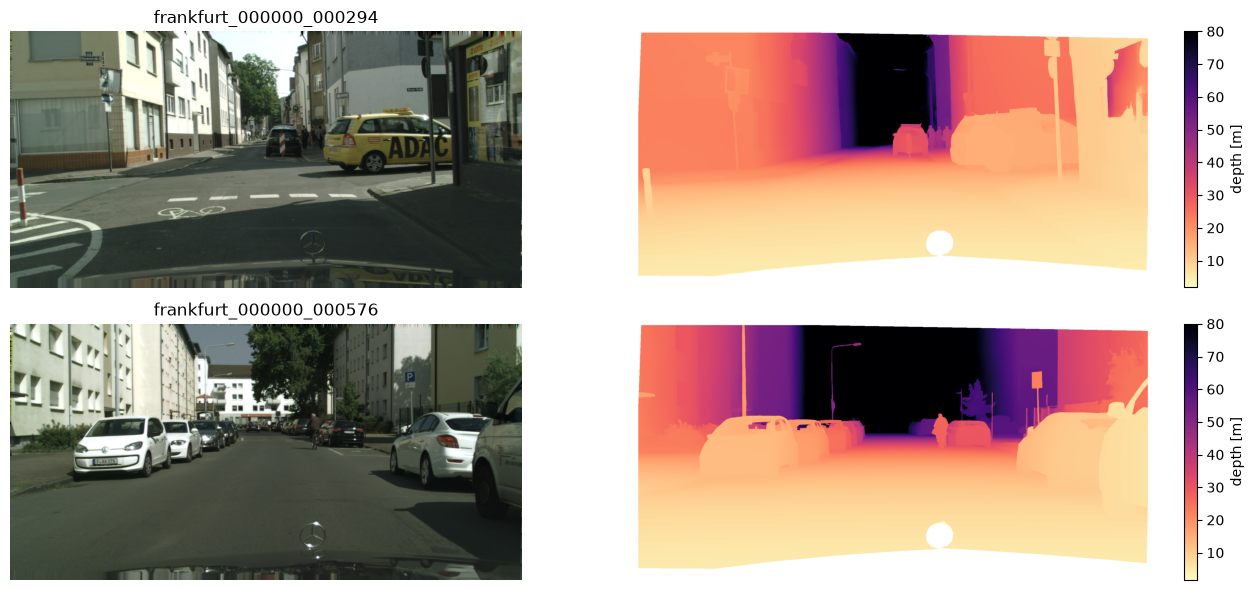

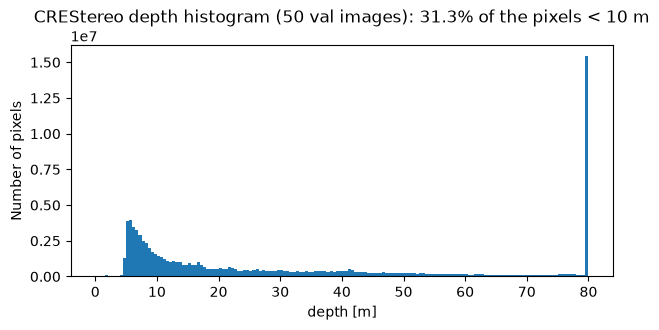

In [1]:
def check_cityscapes_depth(n_hist: int = 50) -> None:
    """
    Show two depth maps, the road depth at the bottom centre and the depth histogram.
    """
    depth_paths = sorted((CS_DEPTH_DIR / "val").glob("*/*_crestereo_depth.png"))
    if not depth_paths:
        print("No depth maps found")
        return

    fig, axs = plt.subplots(2, 2)
    fig.set_size_inches(14, 6)

    for row, depth_path in enumerate(depth_paths[:2]):
        stem = depth_path.name.replace("_crestereo_depth.png", "")
        city = depth_path.parent.name

        img = cv2.cvtColor(cv2.imread(str(CS_ROOT / "leftImg8bit" / "val" / city / f"{stem}_leftImg8bit.png")), cv2.COLOR_BGR2RGB)
        depth = cv2.imread(str(depth_path), cv2.IMREAD_UNCHANGED) / 256.0
        label_ids = cv2.imread(str(CS_ROOT / "gtFine" / "val" / city / f"{stem}_gtFine_labelIds.png"), cv2.IMREAD_UNCHANGED)

        # road pixels (labelId 7) in the bottom-centre region
        H, W = depth.shape
        road = (label_ids == 7) & (depth > 0)
        road[: int(0.8 * H)] = False
        road[:, : W // 3] = False
        road[:, 2 * W // 3:] = False
        road_depth = np.median(depth[road]) if road.any() else float("nan")
        print(f"{stem}: median road depth at the bottom centre = {road_depth:.1f} m")

        axs[row, 0].imshow(img)
        axs[row, 0].set_title(stem)
        axs[row, 0].axis("off")

        im = axs[row, 1].imshow(np.where(depth > 0, depth, np.nan), cmap="magma_r", vmax=80)
        axs[row, 1].axis("off")
        fig.colorbar(im, ax=axs[row, 1], label="depth [m]")

    plt.tight_layout()
    plt.show()

    # histogram of the valid depths
    all_depths = []
    for depth_path in depth_paths[:n_hist]:
        depth = cv2.imread(str(depth_path), cv2.IMREAD_UNCHANGED) / 256.0
        all_depths.append(depth.ravel())
    all_depths = np.concatenate(all_depths)
    all_depths = all_depths[all_depths > 0]

    plt.figure(figsize=(7, 3))
    plt.hist(all_depths, bins=160, range=(0, 80))
    plt.title(f"CREStereo depth histogram ({n_hist} val images): {100 * (all_depths < 10).mean():.1f}% of the pixels < 10 m")
    plt.xlabel("depth [m]")
    plt.ylabel("Number of pixels")
    plt.show()


check_cityscapes_depth()

### NYUv2 (40 classes, 795/654)
Downloads and converts the official labelled NYUv2 subset:
- `nyu_depth_v2_labeled.mat` (2.8 GB, Silberman et al.): RGB, in-painted depth in metres, and the raw 894-class labels.
- `labels40.mat` + `splits.mat` (`ankurhanda/nyuv2-meta-data`): the standard NYU40 labels (Gupta et al.) and the official 795/654 split.

The cell writes `data/nyu/{train,test}/{rgb,depth,seg}/XXXX.png`:
- depth as uint16 millimetres;
- seg as uint8 with 0 = unlabelled and 1..40 = classes.

In [ ]:
NYU_URLS = {
    "nyu_depth_v2_labeled.mat": "http://horatio.cs.nyu.edu/mit/silberman/nyu_depth_v2/nyu_depth_v2_labeled.mat",
    "labels40.mat": "https://github.com/ankurhanda/nyuv2-meta-data/raw/master/labels40.mat",
    "splits.mat": "https://github.com/ankurhanda/nyuv2-meta-data/raw/master/splits.mat",
}


def load_mat_array(path: Path, n: int = 1449) -> np.ndarray:
    """Load the 3-D array that has an axis of length n, as (n, 480, 640).

    Args:
        path: a MATLAB v5 or v7.3 (HDF5) file.
        n: number of images.
    """
    try:
        content = scipy.io.loadmat(path)
        arrays = {key: value for key, value in content.items() if isinstance(value, np.ndarray)}
    except NotImplementedError:
        # MATLAB v7.3 -> HDF5
        with h5py.File(path, "r") as f:
            arrays = {key: np.array(f[key]) for key in f.keys() if isinstance(f[key], h5py.Dataset)}

    array = next(value for value in arrays.values() if value.ndim == 3 and n in value.shape)
    array = np.moveaxis(array, array.shape.index(n), 0)

    # .mat files store the images transposed
    if array.shape[1:] == (640, 480):
        array = array.transpose(0, 2, 1)

    assert array.shape[1:] == (480, 640), array.shape
    return array


def prepare_nyu() -> None:
    """
    Convert the labelled NYUv2 subset into rgb/, depth/ (uint16 mm) and seg/ (NYU40) PNGs for the 795/654 split.
    """
    if len(list((NYU_ROOT / "test" / "seg").glob("*.png"))) == 654:
        print("NYUv2 already prepared")
        return

    raw_dir = NYU_ROOT / "_raw"
    for name, url in NYU_URLS.items():
        download(url, raw_dir / name)

    labels40 = load_mat_array(raw_dir / "labels40.mat")
    assert labels40.max() <= 40
    splits = scipy.io.loadmat(raw_dir / "splits.mat")

    with h5py.File(raw_dir / "nyu_depth_v2_labeled.mat", "r") as f:
        images = f["images"]   # (1449, 3, 640, 480)
        depths = f["depths"]   # (1449, 640, 480)

        for split, key in [("train", "trainNdxs"), ("test", "testNdxs")]:
            indices = splits[key].ravel() - 1   # MATLAB is 1-based

            for sub_dir in ["rgb", "depth", "seg"]:
                (NYU_ROOT / split / sub_dir).mkdir(parents=True, exist_ok=True)

            for i in tqdm(indices, desc=f"NYU {split}"):
                img = np.transpose(images[i], (2, 1, 0))   # (480, 640, 3) RGB
                depth = depths[i].T                         # metres

                cv2.imwrite(str(NYU_ROOT / split / "rgb" / f"{i:04d}.png"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
                cv2.imwrite(str(NYU_ROOT / split / "depth" / f"{i:04d}.png"), np.round(depth * 1000).astype(np.uint16))
                cv2.imwrite(str(NYU_ROOT / split / "seg" / f"{i:04d}.png"), labels40[i].astype(np.uint8))

    for split in ["train", "test"]:
        print(f"{split}: {len(list((NYU_ROOT / split / 'rgb').glob('*.png')))} images")


prepare_nyu()

### Eval-only datasets (for the all-in-one comparison)

#### KITTI Eigen test split

In [ ]:
EIGEN_URL = "https://raw.githubusercontent.com/cleinc/bts/master/train_test_inputs/eigen_test_files_with_gt.txt"
KITTI_RAW_URL = "https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/{d}/{d}_sync.zip"
KITTI_GT_URL = "https://s3.eu-central-1.amazonaws.com/avg-kitti/data_depth_annotated.zip"


def prepare_kitti_eigen_test() -> None:
    """
    Download only the 652 Eigen test frames and their annotated GT, and write data/kitti/eigen_test.txt.
    """
    out_list = KITTI_ROOT / "eigen_test.txt"
    if out_list.exists():
        print(f"KITTI Eigen test ready: {len(out_list.read_text().splitlines())} images")
        return

    # split file: "image_path gt_path focal", lines without GT are dropped
    split_file = download(EIGEN_URL, KITTI_ROOT / "eigen_test_files_with_gt.txt")
    lines = []
    for line in split_file.read_text().splitlines():
        if line.strip() and line.split()[1] != "None":
            lines.append(line.split())

    # annotated GT: extract only the needed maps
    gt_names = {line[1] for line in lines}   # "<drive>_sync/proj_depth/groundtruth/image_02/xxx.png"
    gt_dir = KITTI_ROOT / "depth_annotated"
    gt_missing = False
    for gt_name in gt_names:
        if not any((gt_dir / split / gt_name).exists() for split in ["train", "val"]):
            gt_missing = True
            break

    if gt_missing:
        zip_path = download(KITTI_GT_URL, KITTI_ROOT / "data_depth_annotated.zip")
        extract(zip_path, gt_dir, keep=lambda member: member.split("/", 1)[-1] in gt_names)
        zip_path.unlink()

    # raw drives: extract only the needed frames
    frames = defaultdict(set)
    for line in lines:
        drive_sync = line[0].split("/")[1]
        frames[drive_sync].add(line[0])   # "2011_09_26/<drive>_sync/image_02/data/xxx.png"

    raw_dir = KITTI_ROOT / "raw"
    for drive_sync, needed in tqdm(sorted(frames.items()), desc="KITTI raw drives"):
        if all((raw_dir / frame).exists() for frame in needed):
            continue

        drive = drive_sync[:-len("_sync")]
        zip_path = download(KITTI_RAW_URL.format(d=drive), KITTI_ROOT / f"{drive_sync}.zip")
        extract(zip_path, raw_dir, keep=lambda member: member in needed)
        zip_path.unlink()

    # resolved list "image_path gt_path focal"
    resolved = []
    for img_name, gt_name, focal in lines:
        gt_path = next(gt_dir / split / gt_name for split in ["train", "val"] if (gt_dir / split / gt_name).exists())
        # relative paths, so that data/ can be moved (archives, another pod, the laptop)
        resolved.append(f"{(raw_dir / img_name).relative_to(KITTI_ROOT)} {gt_path.relative_to(KITTI_ROOT)} {focal}")

    out_list.write_text("\n".join(resolved))
    print(f"KITTI Eigen test ready: {len(resolved)} images")


if CFG["zero_shot"]["kitti"]:
    prepare_kitti_eigen_test()

#### SUN RGB-D test split

***NOTE:*** this leaves out the `NYUdata` scenes, because they are NYUv2 images and would leak into a NYU→SUN transfer test.

In [ ]:
def prepare_sunrgbd() -> None:
    """
    Extract the SUN RGB-D test scenes (image, depth_bfx, intrinsics), excluding the NYUdata scenes.
    """
    out_list = SUN_ROOT / "test_scenes.txt"
    if out_list.exists():
        print(f"SUN RGB-D ready: {len(out_list.read_text().splitlines())} scenes")
        return

    # official test list from the toolbox
    toolbox_zip = download("http://rgbd.cs.princeton.edu/data/SUNRGBDtoolbox.zip", SUN_ROOT / "SUNRGBDtoolbox.zip")
    extract(toolbox_zip, SUN_ROOT, keep=lambda member: "traintestSUNRGBD" in member)
    split_mat = next(SUN_ROOT.rglob("allsplit.mat"))
    all_test = scipy.io.loadmat(split_mat)["alltest"].ravel()

    scenes = []
    for entry in all_test:
        scene = str(np.squeeze(entry)).split("SUNRGBD/")[-1].rstrip("/")
        if "NYUdata" not in scene:   # NYUv2 images would leak into a NYU -> SUN transfer
            scenes.append(scene)
    scenes = sorted(scenes)
    scene_set = set(scenes)

    def keep(member: str) -> bool:
        parts = member.split("/")
        for k in range(len(parts) - 1, 0, -1):
            if "/".join(parts[1:k]) in scene_set:   # parts[0] == "SUNRGBD"
                rest = parts[k:]
                return rest[0] in ("image", "depth_bfx") or rest == ["intrinsics.txt"]
        return False

    data_zip = download("http://rgbd.cs.princeton.edu/data/SUNRGBD.zip", SUN_ROOT / "SUNRGBD.zip")
    extract(data_zip, SUN_ROOT, keep=keep)
    data_zip.unlink()

    out_list.write_text("\n".join(scenes))
    print(f"SUN RGB-D ready: {len(scenes)} scenes")


if CFG["zero_shot"]["sunrgbd"]:
    prepare_sunrgbd()

#### ADE20K, VOC 2012 and Pascal Context

In [26]:
SEG_URLS = dict(
    ade20k=["http://data.csail.mit.edu/places/ADEchallenge/ADEChallengeData2016.zip"],
    # official server first, then a mirror of the same file (the Oxford server is often down)
    voc2012=[
        "http://host.robots.ox.ac.uk/pascal/VOC/voc2012/VOCtrainval_11-May-2012.tar",
        "https://data.pjreddie.com/files/VOCtrainval_11-May-2012.tar",
    ],
    pcontext=["https://cs.stanford.edu/~roozbeh/pascal-context/trainval.tar.gz"],
)
PC_VAL_SIZE = 5105


def download_any(urls: List[str], dst: Path) -> Path:
    """Try the URLs in order and return the first successful download.

    Args:
        urls: the official URL and its mirrors.
        dst: the destination path.
    """
    for url in urls:
        try:
            return download(url, dst)
        except requests.RequestException as e:
            print(f"{url} failed ({type(e).__name__}), trying the next one")
    raise RuntimeError(f"No working URL for {dst.name}")



def prepare_ade20k() -> None:
    if (ADE_ROOT / "ADEChallengeData2016" / "annotations" / "validation").exists():
        print("ADE20K ready")
        return

    zip_path = download_any(SEG_URLS["ade20k"], ADE_ROOT / "ADEChallengeData2016.zip")
    extract(zip_path, ADE_ROOT, keep=lambda member: "validation" in member or member.endswith("objectInfo150.csv"))
    zip_path.unlink()
    print("ADE20K ready")


def prepare_voc2012() -> None:
    if (VOC_ROOT / "VOCdevkit" / "VOC2012" / "SegmentationClass").exists():
        print("VOC2012 ready")
        return

    tar_path = download_any(SEG_URLS["voc2012"], VOC_ROOT / "VOC2012.tar")
    # Main/val.txt is needed to rebuild the Pascal Context val split
    extract(
        tar_path,
        VOC_ROOT,
        keep=lambda member: "Segmentation" in member or "JPEGImages" in member or member.endswith("ImageSets/Main/val.txt")
    )
    tar_path.unlink()
    print("VOC2012 ready")


def prepare_pcontext() -> None:
    """
    Pascal Context labels; the images are the VOC 2010 ones, all contained in VOC 2012 (prepare_voc2012 first).
    """
    if (PC_ROOT / "val.txt").exists():
        print("Pascal Context ready")
        return

    # 459-class labels (.mat per image) + labels.txt
    if not list(PC_ROOT.rglob("labels.txt")):
        tar_path = download_any(SEG_URLS["pcontext"], PC_ROOT / "trainval.tar.gz")
        extract(tar_path, PC_ROOT)
        tar_path.unlink()

    # VOC 2010 val = VOC 2012 Main val restricted to the 2010 trainval images (the ones with a PC label)
    labelled = {p.stem for p in PC_ROOT.rglob("*.mat")}
    voc_val = (VOC_ROOT / "VOCdevkit" / "VOC2012" / "ImageSets" / "Main" / "val.txt").read_text().split()
    names = [name for name in voc_val if name in labelled]
    assert len(names) == PC_VAL_SIZE, f"Pascal Context val: {len(names)} images instead of {PC_VAL_SIZE}"

    (PC_ROOT / "val.txt").write_text("\n".join(names))
    print("Pascal Context ready")


if CFG["zero_shot"]["ade20k"]:
    prepare_ade20k()
if CFG["zero_shot"]["voc2012"]:
    prepare_voc2012()
if CFG["zero_shot"]["pcontext"]:
    prepare_pcontext()

ADE20K ready
VOC2012 ready
Pascal Context ready


---
## Final check
This section checks that every prepared dataset in `data/` loads. The `data/` folder is then self-contained and can be copied to another machine as it is, so nothing has to be downloaded or regenerated again (in particular the CREStereo).

cityscapes: 2975 train / 500 val
nyu: 795 train / 654 test
kitti: 652 test images
sunrgbd: 4396 test images
ade20k: 2000 test images
voc2012: 1449 test images
pcontext: 5105 test images


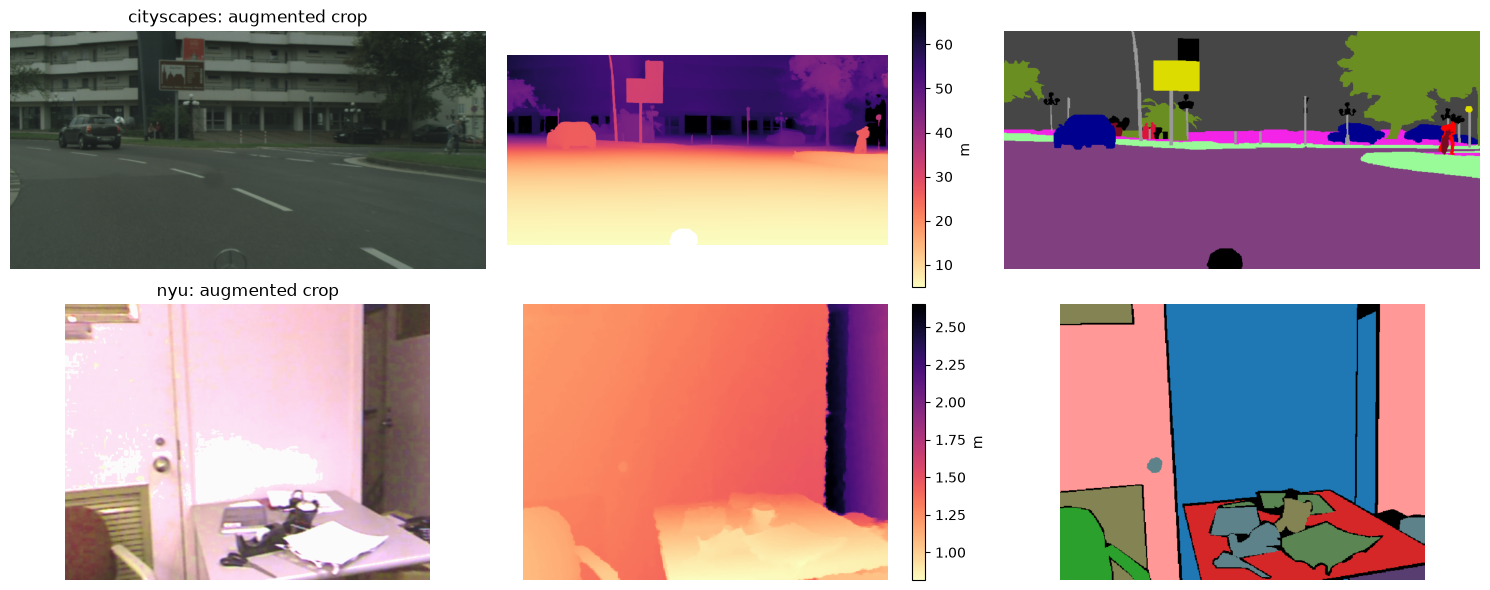

In [6]:
# training / evaluation datasets
for name in ["cityscapes", "nyu"]:
    eval_split = CFG["datasets"][name]["eval_split"]
    train_dataset = make_dataset(name, "train", True)
    eval_dataset = make_dataset(name, eval_split, False)
    print(f"{name}: {len(train_dataset)} train / {len(eval_dataset)} {eval_split}")

# eval-only readers
for kind in ["kitti", "sunrgbd", "ade20k", "voc2012", "pcontext"]:
    try:
        print(f"{kind}: {len(make_eval_dataset(kind))} test images")
    except Exception as e:
        print(f"{kind}: not available ({type(e).__name__}: {e})")

# one augmented training sample per dataset
fig, axs = plt.subplots(2, 3)
fig.set_size_inches(15, 6)

for row, name in enumerate(["cityscapes", "nyu"]):
    sample = make_dataset(name, "train", True)[0]
    depth = sample["depth"][0].numpy()

    axs[row, 0].imshow(denormalize(sample["image"]))
    axs[row, 0].set_title(f"{name}: augmented crop")

    im = axs[row, 1].imshow(np.where(depth > 0, depth, np.nan), cmap="magma_r")
    fig.colorbar(im, ax=axs[row, 1], label="m")

    axs[row, 2].imshow(colorize_seg(sample["seg"].numpy(), PALETTES[name]))

    for ax in axs[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()